# Лабораторная работа № 5. Деревья решений

**Студент:** Войтко Тимофей Дмитриевич, группа 351002  
**Преподаватель:** Лебедевич Артем Владимирович

## Задание

1. Реализовать расчёт критерия Джини.
2. Реализовать расчёт прироста информации.
3. Реализовать не менее двух критериев остановки.
4. Реализовать расчёт метрики модели.
5. Сравнить самописное дерево с `DecisionTreeClassifier` на одинаковых данных. Предсказания должны полностью совпасть.

## 1. Импорты и исходные данные

Для запуска нужны NumPy, Matplotlib и scikit-learn. Если пакеты отсутствуют, установите их в выбранном ядре командой `%pip install numpy matplotlib scikit-learn`. Результаты ниже получены в Python 3.12.

Используем синтетическую выборку из 600 объектов. Стратификация сохраняет доли классов при делении на обучение и тест.

In [1]:
from dataclasses import dataclass

import matplotlib.pyplot as plt
import numpy as np
from sklearn.datasets import make_classification
from sklearn.metrics import ConfusionMatrixDisplay, accuracy_score
from sklearn.model_selection import train_test_split
from sklearn.tree import DecisionTreeClassifier

RANDOM_STATE = 42
MAX_DEPTH = 4
MIN_SAMPLES_SPLIT = 6
MIN_SAMPLES_LEAF = 3

X, y = make_classification(
    n_samples=600,
    n_features=5,
    n_informative=4,
    n_redundant=0,
    class_sep=1.1,
    random_state=RANDOM_STATE,
)
X = X.astype(np.float32)
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.25, stratify=y, random_state=RANDOM_STATE
)

print(f'Обучающая выборка: {X_train.shape[0]} объектов')
print(f'Тестовая выборка: {X_test.shape[0]} объектов')
print(f'Классы в обучающей выборке: {np.bincount(y_train)}')
print(f'Классы в тестовой выборке: {np.bincount(y_test)}')

Обучающая выборка: 450 объектов
Тестовая выборка: 150 объектов
Классы в обучающей выборке: [224 226]
Классы в тестовой выборке: [75 75]


## 2. Критерий Джини и прирост информации

Неоднородность узла $G = 1 - \sum_k p_k^2$, где $p_k$ — доля класса $k$. Если все объекты одного класса, $G=0$.

Для разбиения вычисляем $\Delta G=G_{\text{parent}}-\frac{n_L}{n}G_L-\frac{n_R}{n}G_R$. Чем выше прирост, тем однороднее дочерние узлы с учётом их размеров. В этой работе прирост считается через Джини.

In [2]:
def gini(labels):
    if len(labels) == 0:
        return 0.0
    _, counts = np.unique(labels, return_counts=True)
    probabilities = counts / len(labels)
    return float(1 - np.sum(probabilities ** 2))


def gain(left_labels, right_labels, root_gini):
    left_size = len(left_labels)
    right_size = len(right_labels)
    if left_size == 0 or right_size == 0:
        return 0.0
    total = left_size + right_size
    return root_gini - (
        left_size * gini(left_labels) + right_size * gini(right_labels)
    ) / total

## 3. Узлы, пороги и критерии остановки

В узле перебираются середины между соседними различными значениями каждого признака. Левая ветвь получает объекты со значением не выше порога. Разбиение выбирается по максимальному приросту Джини среди кандидатов с допустимыми размерами листьев.

Рекурсия останавливается при достижении максимальной глубины, при недостаточном числе объектов в узле, при однородном узле или отсутствии допустимого разбиения с положительным приростом. Лист предсказывает самый частый класс. При равенстве частот выбирается меньшая метка.

In [3]:
@dataclass
class Node:
    index: int
    t: float
    true_branch: 'Node | Leaf'
    false_branch: 'Node | Leaf'


@dataclass
class Leaf:
    prediction: int


def split(data, labels, column_index, threshold):
    left_mask = data[:, column_index].astype(np.float64) <= threshold
    return data[left_mask], data[~left_mask], labels[left_mask], labels[~left_mask]


def find_best_split(data, labels, min_samples_leaf):
    root_gini = gini(labels)
    best_gain, best_threshold, best_index = 0.0, None, None
    for index in range(data.shape[1]):
        column = data[:, index].astype(np.float64)
        values = np.unique(column)
        thresholds = (values[:-1] + values[1:]) / 2
        for threshold in thresholds:
            left_mask = column <= threshold
            left_size = np.count_nonzero(left_mask)
            if min(left_size, len(labels) - left_size) < min_samples_leaf:
                continue
            current_gain = gain(labels[left_mask], labels[~left_mask], root_gini)
            if current_gain > best_gain:
                best_gain, best_threshold, best_index = current_gain, float(threshold), index
    return best_gain, best_threshold, best_index


def majority_leaf(labels):
    classes, counts = np.unique(labels, return_counts=True)
    return Leaf(int(classes[np.argmax(counts)]))


def build_tree(data, labels, max_depth, min_samples_split, min_samples_leaf, depth=0):
    if depth >= max_depth or len(labels) < min_samples_split or gini(labels) == 0:
        return majority_leaf(labels)
    best_gain, threshold, index = find_best_split(data, labels, min_samples_leaf)
    if best_gain <= 0:
        return majority_leaf(labels)
    left_data, right_data, left_labels, right_labels = split(data, labels, index, threshold)
    left_branch = build_tree(
        left_data, left_labels, max_depth, min_samples_split, min_samples_leaf, depth + 1
    )
    right_branch = build_tree(
        right_data, right_labels, max_depth, min_samples_split, min_samples_leaf, depth + 1
    )
    return Node(index, threshold, left_branch, right_branch)

## 4. Прогноз и метрика

Для объекта последовательно проверяем условия узлов до достижения листа. Accuracy — доля объектов, для которых прогноз совпал с истинным классом.

In [4]:
def classify_object(obj, node):
    while isinstance(node, Node):
        if float(obj[node.index]) <= node.t:
            node = node.true_branch
        else:
            node = node.false_branch
    return node.prediction


def predict(data, tree):
    return np.array([classify_object(obj, tree) for obj in data])


def accuracy_metric(actual, predicted):
    actual = np.asarray(actual)
    predicted = np.asarray(predicted)
    if actual.ndim != 1 or actual.shape != predicted.shape or actual.size == 0:
        raise ValueError('Ожидаются непустые одномерные массивы одинаковой длины')
    return float(np.mean(actual == predicted))

## 5. Сравнение с `DecisionTreeClassifier`

Обучаем обе модели на одних данных с одинаковыми ограничениями. Сравниваем и значения Accuracy, и предсказания по каждому объекту. Равная Accuracy сама по себе допускает ошибки на разных объектах.

Обучающая: Accuracy = 0.8422 / 0.8422
Совпало прогнозов: 450 из 450
Тестовая: Accuracy = 0.7933 / 0.7933
Совпало прогнозов: 150 из 150


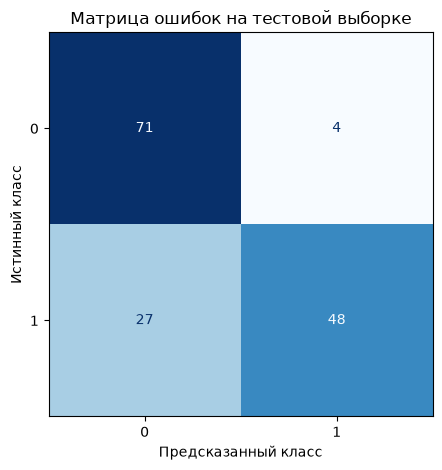

In [5]:
my_tree = build_tree(X_train, y_train, MAX_DEPTH, MIN_SAMPLES_SPLIT, MIN_SAMPLES_LEAF)
reference = DecisionTreeClassifier(
    criterion='gini',
    max_depth=MAX_DEPTH,
    min_samples_split=MIN_SAMPLES_SPLIT,
    min_samples_leaf=MIN_SAMPLES_LEAF,
    random_state=RANDOM_STATE,
)
reference.fit(X_train, y_train)

results = {}
for name, features, labels in (
    ('Обучающая', X_train, y_train),
    ('Тестовая', X_test, y_test),
):
    own = predict(features, my_tree)
    expected = reference.predict(features)
    own_accuracy = accuracy_metric(labels, own)
    sklearn_accuracy = float(accuracy_score(labels, expected))
    mismatches = int(np.count_nonzero(own != expected))
    results[name] = (len(labels), own_accuracy, sklearn_accuracy, mismatches)
    print(f'{name}: Accuracy = {own_accuracy:.4f} / {sklearn_accuracy:.4f}')
    print(f'Совпало прогнозов: {len(labels) - mismatches} из {len(labels)}')
    assert np.array_equal(own, expected)
    assert own_accuracy == sklearn_accuracy

test_predictions = predict(X_test, my_tree)
ConfusionMatrixDisplay.from_predictions(
    y_test, test_predictions, cmap='Blues', colorbar=False, values_format='d'
)
plt.title('Матрица ошибок на тестовой выборке')
plt.xlabel('Предсказанный класс')
plt.ylabel('Истинный класс')
plt.tight_layout()
plt.show()

## Вывод

Самописное дерево использует критерий Джини, прирост информации и ограничения роста. При выбранных данных и настройках его предсказания для всех обучающих и тестовых объектов совпали с предсказаниями `DecisionTreeClassifier`.